# 03 - First Text Models

## Objective

The objective is to obtain the first simple modelling results for the Rakuten product-classification task. Two models are compared:

1. a minimum baseline that always predicts the largest class;
2. a text baseline using TF-IDF and a Linear SVM.

Both models use the existing shared training/validation split. The official test data is not used because its labels are unavailable.

## 1. Load the Prepared Text

The processed file contains cleaned text, the correct product category and the shared split. Product and image identifiers are not used as model features.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score
from sklearn.svm import LinearSVC

from src.data_utils import load_merged_data

processed_path = Path("../data/processed/text_train_processed.csv")
data = pd.read_csv(processed_path)

model_train = data[data["split"] == "train"].copy()
model_validation = data[data["split"] == "validation"].copy()

print(f"Training products: {len(model_train):,}")
print(f"Validation products: {len(model_validation):,}")

Training products: 67,932
Validation products: 16,984


## 2. Largest-Class Baseline

This baseline predicts the most common training category for every validation product. It ignores the text completely and establishes a minimum score that a useful model should beat.

In [2]:
y_train = model_train["prdtypecode"]
y_validation = model_validation["prdtypecode"]

largest_class = y_train.value_counts().idxmax()
majority_predictions = np.full(len(model_validation), largest_class)

majority_weighted_f1 = f1_score(
    y_validation, majority_predictions, average="weighted"
)
majority_macro_f1 = f1_score(
    y_validation, majority_predictions, average="macro"
)

print(f"Largest class: {largest_class}")
print(f"Weighted F1: {majority_weighted_f1:.4f}")
print(f"Macro F1: {majority_macro_f1:.4f}")

Largest class: 2583
Weighted F1: 0.0258
Macro F1: 0.0080


## 3. Convert Text into TF-IDF Features

Machine-learning models require numbers rather than sentences. TF-IDF converts the cleaned combined text into numerical word features.

The vocabulary is learned from training text only. The fitted vectorizer then transforms the validation text without learning from it.

In [3]:
vectorizer = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    min_df=2,
)

X_train = vectorizer.fit_transform(model_train["text_combined"])
X_validation = vectorizer.transform(model_validation["text_combined"])

print(f"Training matrix: {X_train.shape}")
print(f"Validation matrix: {X_validation.shape}")

Training matrix: (67932, 50000)
Validation matrix: (16984, 50000)


## 4. Train the First Text Classifier

A Linear SVM is a standard, efficient baseline for high-dimensional TF-IDF text features. It learns from the training products and predicts categories for the unseen validation products.

In [4]:
text_model = LinearSVC(random_state=42)
text_model.fit(X_train, y_train)
text_predictions = text_model.predict(X_validation)

text_weighted_f1 = f1_score(
    y_validation, text_predictions, average="weighted"
)
text_macro_f1 = f1_score(
    y_validation, text_predictions, average="macro"
)

## 5. Compare the Results

Weighted F1 gives more influence to large classes. Macro F1 gives equal importance to every class and therefore reveals whether smaller classes are being neglected.

In [5]:
results = pd.DataFrame({
    "model": ["Largest-class baseline", "TF-IDF + Linear SVM"],
    "weighted_f1": [majority_weighted_f1, text_weighted_f1],
    "macro_f1": [majority_macro_f1, text_macro_f1],
})

results.round(4)

,model,weighted_f1,macro_f1
0,Largest-class baseline,0.0258,0.0080
1,TF-IDF + Linear SVM,0.8274,0.8156


## 6. Did the Text Cleaning Help?

To measure the effect of cleaning, the same model is trained again on the raw text. Only the text changes: same products, same split, same TF-IDF settings and same Linear SVM. Any difference in score therefore comes from the cleaning.

The raw text is the original designation and description joined together, with nothing removed.

In [6]:
raw_data = load_merged_data()
raw_text = raw_data["designation"].fillna("") + " " + raw_data["description"].fillna("")

model_train["text_raw"] = model_train["row_id"].map(raw_text)
model_validation["text_raw"] = model_validation["row_id"].map(raw_text)

model_validation[["text_raw", "text_combined"]].head(3)

,text_raw,text_combined
1,Journal Des Arts (Le) N° 133 Du 28/09/2001 - L...,journal des arts (le) n° 133 du 28/09/2001 - l...
6,Christof E: Bildungsprozessen Auf Der Spur,christof e: bildungsprozessen auf der spur
12,Peaceable Kingdom Wheres Bear? The Hide And Fi...,peaceable kingdom wheres bear? the hide and fi...


In [7]:
raw_vectorizer = TfidfVectorizer(
    max_features=50_000,
    ngram_range=(1, 2),
    min_df=2,
)

X_train_raw = raw_vectorizer.fit_transform(model_train["text_raw"])
X_validation_raw = raw_vectorizer.transform(model_validation["text_raw"])

raw_model = LinearSVC(random_state=42)
raw_model.fit(X_train_raw, y_train)
raw_predictions = raw_model.predict(X_validation_raw)

raw_weighted_f1 = f1_score(y_validation, raw_predictions, average="weighted")
raw_macro_f1 = f1_score(y_validation, raw_predictions, average="macro")

In [8]:
cleaning_results = pd.DataFrame({
    "text used": ["raw text", "cleaned text"],
    "weighted_f1": [raw_weighted_f1, text_weighted_f1],
    "macro_f1": [raw_macro_f1, text_macro_f1],
})

cleaning_results.round(4)

,text used,weighted_f1,macro_f1
0,raw text,0.8276,0.8167
1,cleaned text,0.8274,0.8156


In [9]:
has_html = model_validation["text_raw"].str.contains("<", regex=False)
same_prediction = raw_predictions == text_predictions

print(f"Validation products with HTML tags in the raw text: {has_html.mean():.1%}")
print(f"Products where both models predict the same class: {same_prediction.mean():.1%}")

Validation products with HTML tags in the raw text: 18.7%
Products where both models predict the same class: 97.7%


### Observation

The two scores are almost the same, so cleaning does not improve this baseline. The check above shows that this is not an error: many raw texts really contain HTML, yet the two models predict the same class for almost every product.

There are three reasons:

- **TF-IDF needs consistent words, not readable words.** In the raw text, `d&eacute;coration` becomes the tokens `eacute` and `coration`. The broken word `coration` appears the same way in training and validation, so the model learns it like any other word.
- **HTML is not only noise.** Some sellers use HTML templates and sell certain types of product, so terms such as `br` and `li` carry a little class information. Cleaning removes noise but also this small signal, and the two effects cancel out.
- **Most of the information is in the title.** Titles are short and contain very little HTML, and the title words are the same in both versions.

The cleaning is still kept. It makes the text readable, it gives correct top words per class (section 5 of `02_preprocessing_text.ipynb`), and later models with a word limit, such as transformers, should not spend that limit on HTML tags.

## 7. Plot the TF-IDF Space and the SVM Errors

Each product is a point with 50,000 TF-IDF values, which cannot be drawn directly. Two steps reduce it to two dimensions:

1. **Truncated SVD** compresses the 50,000 values into 50. It is fitted on training rows only.
2. **t-SNE** places the products on a 2D map so that products with similar text sit close together.

A random sample of 3,000 validation products keeps t-SNE fast.

The map shows neighbourhoods, not the real SVM boundary. The SVM separates classes in all 50,000 dimensions, so its boundary cannot be drawn in 2D. Distances between far-apart groups on a t-SNE map have no meaning.

In [10]:
rng = np.random.default_rng(42)
sample = rng.choice(X_validation.shape[0], size=3_000, replace=False)

X_sample = X_validation[sample]
true_sample = y_validation.to_numpy()[sample]
predicted_sample = text_predictions[sample]

svd = TruncatedSVD(n_components=50, random_state=42)
svd.fit(X_train)
X_sample_50 = svd.transform(X_sample)

tsne = TSNE(n_components=2, random_state=42)
points = tsne.fit_transform(X_sample_50)

The left map highlights classes 10, 2403 and 2705. They are the three book classes and the most frequent confusions of the SVM. The right map shows which sampled products the SVM classifies wrongly.

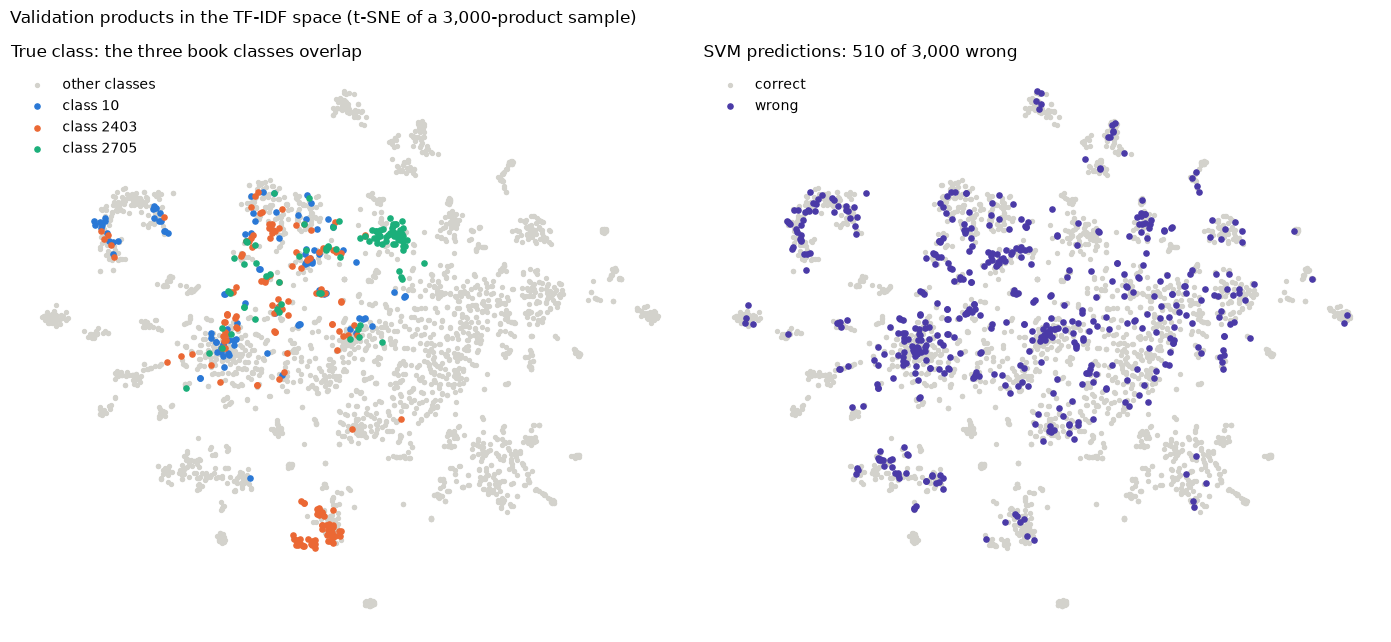

In [11]:
book_classes = {10: "#2a78d6", 2403: "#eb6834", 2705: "#1baf7a"}
grey = "#d3d2cc"
is_correct = true_sample == predicted_sample
is_other_class = ~np.isin(true_sample, list(book_classes))

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)

ax_left.scatter(points[is_other_class, 0], points[is_other_class, 1], s=8, color=grey, label="other classes")
for label, color in book_classes.items():
    is_class = true_sample == label
    ax_left.scatter(points[is_class, 0], points[is_class, 1], s=14, color=color, label=f"class {label}")
ax_left.set_title("True class: the three book classes overlap", loc="left")
ax_left.legend(frameon=False, loc="upper left")

ax_right.scatter(points[is_correct, 0], points[is_correct, 1], s=8, color=grey, label="correct")
ax_right.scatter(points[~is_correct, 0], points[~is_correct, 1], s=14, color="#4a3aa7", label="wrong")
ax_right.set_title(f"SVM predictions: {(~is_correct).sum()} of {len(sample):,} wrong", loc="left")
ax_right.legend(frameon=False, loc="upper left")

for ax in (ax_left, ax_right):
    ax.set_xticks([])
    ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(False)

fig.suptitle("Validation products in the TF-IDF space (t-SNE of a 3,000-product sample)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### Observation

- Many classes form their own tight group. Products in these groups are almost always classified correctly.
- The three book classes are mixed together in the same region. Their titles use similar words, so TF-IDF places them close together.
- The SVM errors gather in these mixed regions and in the crowded centre of the map, where products from different classes share general words.
- This suggests that the remaining errors come from classes whose text is too similar, not from a bug. Images may help separate them later.

## Conclusion

The largest-class baseline provides the minimum reference score. The TF-IDF model tests whether the cleaned product text contains useful category information. These are initial results, not a final optimized model.

The next text-modelling step is to examine per-class performance and the most frequent classification errors before changing model settings.